# 04 · Width extraction step by step (paper Sec. 2.3, Fig. *extraction*, Eq. 8–11)

One capture is followed through the full pipeline:
ROI → barcode crop → **Gaussian blur → Otsu** → per-scan-line dark runs → **matrix M** → μⱼ → mm.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/images/1752392841.png` + its corners |
| **Outputs** | `results/figures/fig_extraction.png`, `fig_matrix_M.png` |
| **Runtime** | < 5 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [ ]:
from visioncrack.width import blur_gray, binarize, measurement_matrix
caps, _ = vc.load_table1()
roi = vc.preview_roi((2160, 3840), (430, 932))
img = vc.read_rgb(caps.path[0])
m = vc.measure_capture(img, caps.bbox[0], roi)
print('barcode crop', m.barcode_box, '| ET crop', m.et_box, '| Otsu threshold', m.barcode_thresh)

barcode crop (703, 2966, 1444, 3275) | ET crop (703, 2466, 1444, 2766) | Otsu threshold 107.0


## Crops and binarization
The Otsu threshold is found on the **barcode** crop and reused for the ET crop, so both are binarized under the same lighting.
The ET crop is a fixed band 200–500 px above the barcode crop (`constants.ET_BAND_*`).

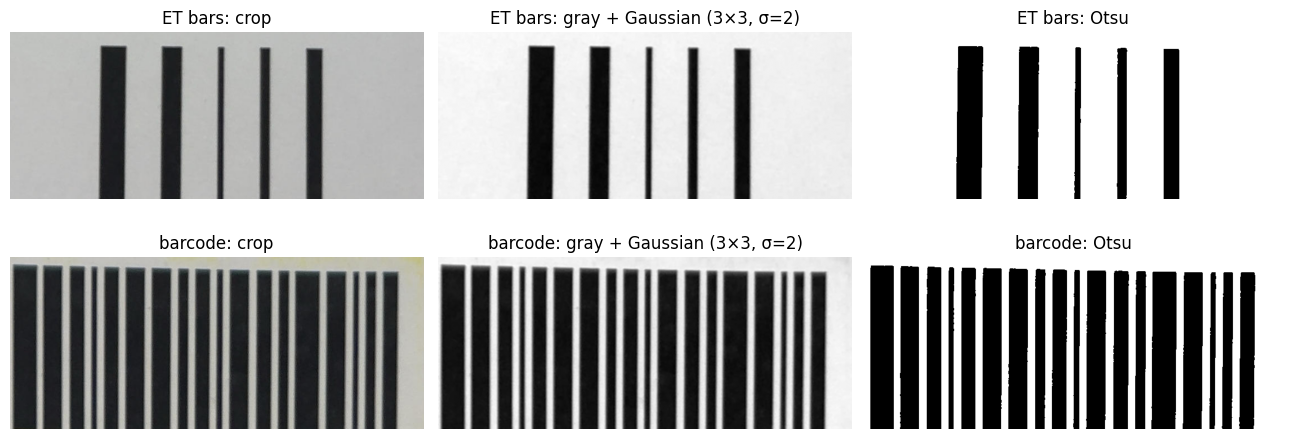

In [ ]:
def crop(b): x0, y0, x1, y1 = b; return img[y0:y1, x0:x1]
bc, et = crop(m.barcode_box), crop(m.et_box)
g_bc, g_et = blur_gray(bc), blur_gray(et)
_, b_bc = binarize(g_bc); _, b_et = binarize(g_et, m.barcode_thresh)

fig, ax = plt.subplots(2, 3, figsize=(13, 5))
for r, (rgb, g, b, name) in enumerate([(et, g_et, b_et, 'ET bars'), (bc, g_bc, b_bc, 'barcode')]):
    for c, (im, t) in enumerate([(rgb, 'crop'), (g, 'gray + Gaussian (3×3, σ=2)'), (b, 'Otsu')]):
        ax[r, c].imshow(im, cmap=None if c == 0 else 'gray'); ax[r, c].set_title(f'{name}: {t}'); ax[r, c].axis('off')
plt.tight_layout(); plt.savefig(FIG / 'fig_extraction.png', dpi=200); plt.show()

## Measurement matrix M
Every scan line that shows exactly 5 dark runs (> 6 px) becomes one row of **M**.
Columns are in the printed left-to-right order, which is ET class `(5, 4, 1, 2, 3)`.

M shape (scan lines × bars): (268, 5)


,bar 1 (ET-5),bar 2 (ET-4),bar 3 (ET-1),bar 4 (ET-2),bar 5 (ET-3)
count,268.00,268.00,268.00,268.00,268.00
mean,45.09,35.54,10.27,16.96,27.99
std,0.35,0.50,0.45,0.33,0.09
min,44.00,35.00,10.00,16.00,27.00
25%,45.00,35.00,10.00,17.00,28.00
50%,45.00,36.00,10.00,17.00,28.00
75%,45.00,36.00,11.00,17.00,28.00
max,46.00,36.00,11.00,18.00,28.00


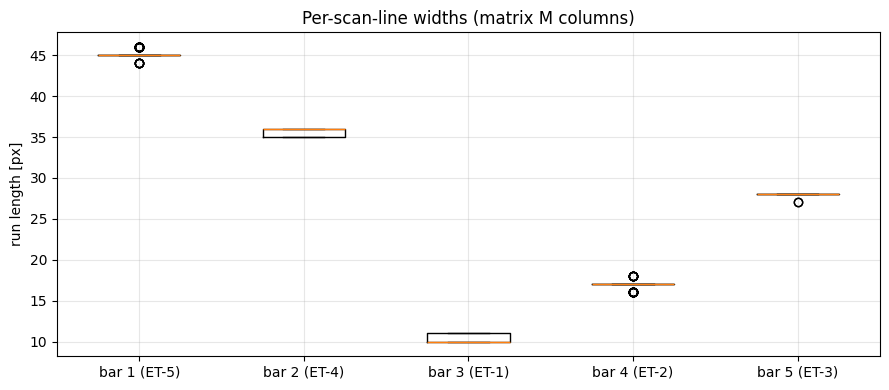

In [ ]:
M = m.et_M
print('M shape (scan lines × bars):', M.shape)
cols = [f'bar {i+1} (ET-{c})' for i, c in enumerate(vc.constants.ET_LAYOUT)]
display(pd.DataFrame(M, columns=cols).describe().round(2))

plt.figure(figsize=(9, 4))
plt.boxplot(M, tick_labels=cols)
plt.ylabel('run length [px]'); plt.title('Per-scan-line widths (matrix M columns)')
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(FIG / 'fig_matrix_M.png', dpi=200); plt.show()

## μⱼ and conversion to mm (Eq. 10–11)

In [ ]:
pd.DataFrame({'GT [mm]': vc.ET_GT_MM, 'μ [px]': m.widths_px.round(2),
              'width [mm]': m.widths_mm.round(3)}, index=[f'ET-{i+1}' for i in range(5)])

,GT [mm],μ [px],width [mm]
ET-1,0.55,10.27,0.644
ET-2,1.10,17.00,1.066
ET-3,1.65,28.00,1.757
ET-4,2.20,35.54,2.229
ET-5,2.75,45.00,2.823


The 18 barcode bars go through the same steps. Their widths group into the 5 thickness classes (0.5–2.5 mm),
which is what the decoder uses.

In [ ]:
print('barcode M shape:', m.barcode_M.shape)
from visioncrack.width import column_means
print('barcode bar widths [px]:', column_means(m.barcode_M).round(1))

barcode M shape: (280, 18)
barcode bar widths [px]: [42.  33.  26.   9.  25.  34.  34.  18.  26.  10.3 34.  26.3 18.  43.
 34.   9.4 17.5 26. ]
